# Data analysis of experiments with HOpt as sourceof uncertainty

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib
import scipy.stats
import yaml

import aggregated_use_cases_analysis.data as data
import aggregated_use_cases_analysis.visualization as visualization

import experiment_runner.run.experiment_config as experiment_config

from tomlkit import parse

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
SMALL_SIZE = 12
MEDIUM_SIZE = 14
BIGGER_SIZE = 16
LARGE_SIZE = 18

plt.rc('axes', titlesize=BIGGER_SIZE)  # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc('ytick', labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)  # legend fontsize
plt.rc('figure', titlesize=LARGE_SIZE)  # fontsize of the figure title


## Read data

In [4]:
PATH_EXPERIMENTS = pathlib.Path("/beegfs/ws/0/s4610340-isml/simpsons/experiments")
EXPERIMENTS = [
    "10_simpsons_hopt_tpe_SGDwlrs_seeds",
    "11_simpsons_hopt_tpe_AdamW_seeds",
    # "12_simpsons_hopt_tpe_Adamax_seeds",
    # "13_simpsons_hopt_tpe_Adam_seeds",
    # "14_simpsons_hopt_tpe_Adagrad_seeds",
    # "15_simpsons_hopt_tpe_RMSprop_seeds"
]

In [5]:
DF_RESULTS = data.read.read_hopt_experiments([
    PATH_EXPERIMENTS / name for name in EXPERIMENTS
])

DF_RESULTS

/beegfs/.global0/ws/s4610340-isml/.dev/.yahor/statistics-in-machine-learning/aggregated_use_cases_analysis/py/src/aggregated_use_cases_analysis/data/read.py:30: DtypeWarning: Columns (47,50,51,52,64,65,67) have mixed types. Specify dtype option on import or set low_memory=False.
  df_oo_results = pd.read_csv(


time  \
experiment                         omniopt_seed hopt_iter                        
10_simpsons_hopt_tpe_SGDwlrs_seeds 2832         0          2024-01-26 09:47:39   
                                                1          2024-01-26 09:47:39   
                                                2          2024-01-26 09:47:39   
                                                3          2024-01-26 09:47:40   
                                                4          2024-01-26 09:47:42   
...                                                                        ...   
11_simpsons_hopt_tpe_AdamW_seeds   4547         207        2024-02-12 07:41:07   
                                                208        2024-02-12 07:42:33   
                                                209        2024-02-12 07:42:34   
                                                210        2024-02-12 07:43:03   
                                                211        2024-02-12 07:43:46   

                                                                      0  \
experiment                         omniopt_seed hopt_iter                 
10_simpsons_hopt_tpe_SGDwlrs_seeds 2832         0          1.240730e+17   
                                                1          1.240730e+17   
                                                2          1.240730e+17   
                                                3          1.240730e+17   
                                                4          1.240730e+17   
...                                                                 ...   
11_simpsons_hopt_tpe_AdamW_seeds   4547         207        1.240730e+17   
                                                208        1.240730e+17   
                                                209        1.240730e+17   
                                                210        1.240730e+17   
                                                211        1.240730e+17   

                                                                      1    10  \
experiment                         omniopt_seed hopt_iter                       
10_simpsons_hopt_tpe_SGDwlrs_seeds 2832         0          1.240730e+17  52.0   
                                                1          1.240730e+17  48.0   
                                                2          1.240730e+17  52.0   
                                                3          1.240730e+17  52.0   
                                                4          1.240730e+17  50.0   
...                                                                 ...   ...   
11_simpsons_hopt_tpe_AdamW_seeds   4547         207        1.240730e+17   NaN   
                                                208        1.240730e+17   NaN   
                                                209        1.240730e+17   NaN   
                                                210        1.240730e+17   NaN   
                                                211        1.240730e+17   NaN   

                                                           11  12  \
experiment                         omniopt_seed hopt_iter           
10_simpsons_hopt_tpe_SGDwlrs_seeds 2832         0         NaN NaN   
                                                1         NaN NaN   
                                                2         NaN NaN   
                                                3         NaN NaN   
                                                4         NaN NaN   
...                                                        ..  ..   
11_simpsons_hopt_tpe_AdamW_seeds   4547         207       NaN NaN   
                                                208       NaN NaN   
                                                209       NaN NaN   
                                                210       NaN NaN   
                                                211       NaN NaN   

                                                                      2  \
expe

In [6]:
def find_config(exp_path: pathlib.Path) -> str:
    return exp_path.glob("*.toml")[0]

experiment_configs: dict[str, experiment_config.ExperimentConfig] = {
    experiment: experiment_config.read_experiment_config(next((PATH_EXPERIMENTS / experiment).glob("*.toml")))
    for experiment in EXPERIMENTS
}

## Process data

In [7]:
DF_RESULTS.shape

(232909, 72)

### Check NaN

In [7]:
DF_RESULTS.loc[DF_RESULTS["RESULT"].isna()].shape[0]

207

In [8]:
DF_RESULTS.loc[DF_RESULTS["ExperimentConfig.num_epochs"].isna()].shape[0]

207

In [17]:
DF_RESULTS.loc[DF_RESULTS["RESULT"].isna()]

time   0   1  10  11  \
experiment                       omniopt_seed hopt_iter                        
11_simpsons_hopt_tpe_AdamW_seeds 159          0          NaN NaN NaN NaN NaN   
                                              1          NaN NaN NaN NaN NaN   
                                              2          NaN NaN NaN NaN NaN   
                                              3          NaN NaN NaN NaN NaN   
                                              4          NaN NaN NaN NaN NaN   
...                                                      ...  ..  ..  ..  ..   
                                              202        NaN NaN NaN NaN NaN   
                                              203        NaN NaN NaN NaN NaN   
                                              204        NaN NaN NaN NaN NaN   
                                              205        NaN NaN NaN NaN NaN   
                                              206        NaN NaN NaN NaN NaN   

                                                         12   2   3   4   5  \
experiment                       omniopt_seed hopt_iter                       
11_simpsons_hopt_tpe_AdamW_seeds 159          0         NaN NaN NaN NaN NaN   
                                              1         NaN NaN NaN NaN NaN   
                                              2         NaN NaN NaN NaN NaN   
                                              3         NaN NaN NaN NaN NaN   
                                              4         NaN NaN NaN NaN NaN   
...                                                      ..  ..  ..  ..  ..   
                                              202       NaN NaN NaN NaN NaN   
                                              203       NaN NaN NaN NaN NaN   
                                              204       NaN NaN NaN NaN NaN   
                                              205       NaN NaN NaN NaN NaN   
                                              206       NaN NaN NaN NaN NaN   

                                                         ...  \
experiment                       omniopt_seed hopt_iter  ...   
11_simpsons_hopt_tpe_AdamW_seeds 159          0          ...   
                                              1          ...   
                                              2          ...   
                                              3          ...   
                                              4          ...   
...                                                      ...   
                                              202        ...   
                                              203        ...   
                                              204        ...   
                                              205        ...   
                                              206        ...   

                                                         RESULT                \
experiment                       omniopt_seed hopt_iter                         
11_simpsons_hopt_tpe_AdamW_seeds 159          0                      0.169254   
                                              1                      0.892537   
                                              2                      0.223881   
                                              3                      0.171343   
                                              4                      0.208358   
...                                                                       ...   
                                              202                    0.180896   
                                              203                    0.196119   
                                              204                    0.168955   
                                              205                    0.139104   
                                              206                    0.186567   

                                                         datapoints   \
experiment                  

### Write distribution

In [14]:
evals_thr = 198

def get_seed_min_series(df) -> pd.Series:
    idx_min = df["RESULT"].idxmin()
    return df.loc[idx_min]

for experiment, df_experiment in DF_RESULTS.groupby(["experiment"], as_index=False):
    df_experiment = df_experiment.sort_index()
    df_max_hopt_iter = df_experiment.reset_index(level="hopt_iter", drop=False).groupby(["omniopt_seed"])["hopt_iter"].max()
    seeds_with_sufficient_evals = df_max_hopt_iter.loc[df_max_hopt_iter>=evals_thr].index.get_level_values("omniopt_seed")
    df_experiment = df_experiment.loc[pd.IndexSlice[:, seeds_with_sufficient_evals, :evals_thr]]

    cols_config = [col for col in df_experiment.columns if col.startswith("ExperimentConfig")]
    
    df = df_experiment.groupby(["omniopt_seed"]).apply(get_seed_min_series)
    df["N_evals"] = evals_thr
    df = df[[*cols_config, "N_evals", "RESULT"]]

    print(f"experiment {experiment}: total values {len(df)}")

    df.to_csv(PATH_EXPERIMENTS / experiment / "data" / "processed" / "hopt" / "metric_values.csv", index=True)

experiment 10_simpsons_hopt_tpe_SGDwlrs_seeds: total values 511


KeyError: nan

### Get minimal number of iterations

In [34]:
N_hopt_iter = min(e.DATA.max_evals for e in experiment_configs.values())
N_hopt_iter

200

### Remove seeds with unsufficient number of iterations 

In [18]:
df_max_hopt_iter = DF_RESULTS.reset_index(level="hopt_iter", drop=False).groupby(["experiment", "omniopt_seed"])["hopt_iter"].max()

for experiment_name, df_experiment in DF_RESULTS.groupby("experiment"):
        df_max_hopt_iter = df_experiment.reset_index(level="hopt_iter", drop=False).groupby(["experiment", "omniopt_seed"])["hopt_iter"].max()
        print("--------")
        print(experiment_name)
        print("Max iterations < 198:")
        print(df_max_hopt_iter.loc[df_max_hopt_iter<198])
        print("Houpt iterations: ")
        print(df_max_hopt_iter.value_counts().sort_index())


--------
10_simpsons_hopt_tpe_SGDwlrs_seeds
Max iterations < 198:
experiment                          omniopt_seed
10_simpsons_hopt_tpe_SGDwlrs_seeds  719               4
                                    1015              4
                                    1223              5
                                    1279              4
                                    2140              3
                                    2399              5
                                    2773              3
                                    3214              4
                                    4336              4
                                    5037              4
                                    5554              2
                                    5677              4
                                    6496              7
                                    6733              4
                                    7101              3
                                    8190     

In [29]:
df_max_hopt_iter.loc[pd.IndexSlice["11_simpsons_hopt_tpe_AdamW_seeds", 1877]]

197

In [28]:
err_logs = list(pathlib.Path("/beegfs/ws/0/s4610340-isml/simpsons/experiments/11_simpsons_hopt_tpe_AdamW_seeds/omniopt/projects/11_simpsons_hopt_tpe_AdamW_seeds_SEED_897/singlelogs").glob("*.stderr"))
uniq_logs = set()
for err_log_file in err_logs:
    logs = err_log_file.read_text()
    uniq_logs.add(logs)
uniq_logs

{'/bin/bash: warning: setlocale: LC_ALL: cannot change locale (en_US.UTF-8)\n',
 '/bin/bash: warning: setlocale: LC_ALL: cannot change locale (en_US.UTF-8)\n/bin/bash: warning: setlocale: LC_ALL: cannot change locale (en_US.UTF-8)\n'}

## Explore

### HOpt paths

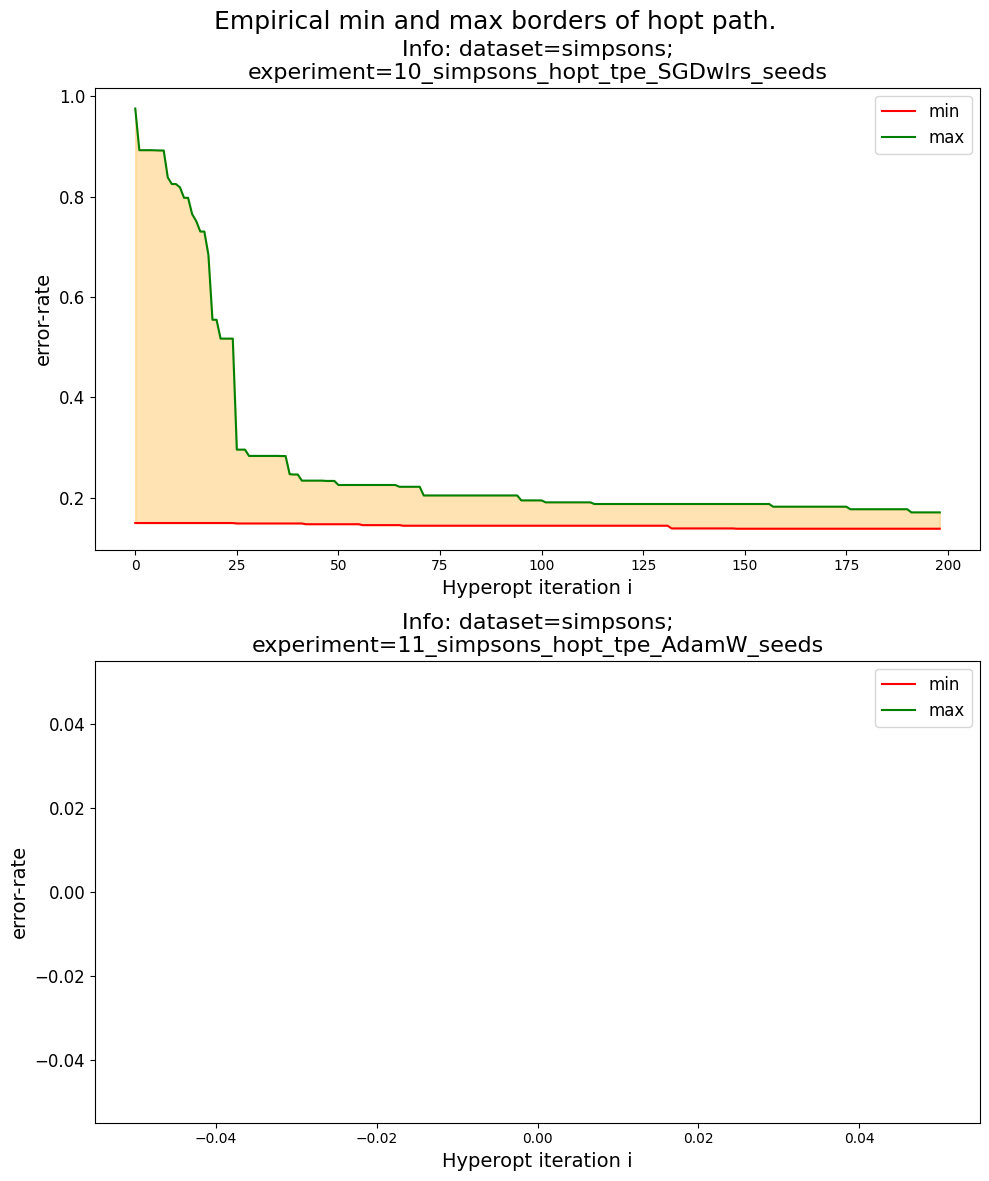

In [19]:
DATASET_NAME = "simpsons"
ALGORITHM_NAME = "tpe.suggest"
METRIC = "error-rate"

evals_thr = 198

fig, axs = plt.subplots(nrows=len(EXPERIMENTS), figsize=(10, 6 * len(EXPERIMENTS)))
fig.suptitle("Empirical min and max borders of hopt path.")

for (experiment, df_experiment), ax in zip(DF_RESULTS.groupby("experiment"), axs):
    df_experiment = df_experiment.sort_index()
    df_max_hopt_iter = df_experiment.reset_index(level="hopt_iter", drop=False).groupby(["experiment", "omniopt_seed"])["hopt_iter"].max()
    seeds_with_sufficient_evals = df_max_hopt_iter.loc[df_max_hopt_iter>=evals_thr].index.get_level_values("omniopt_seed")
    df_experiment = df_experiment.loc[pd.IndexSlice[:, seeds_with_sufficient_evals, :evals_thr]]
    #df_experiment.loc[]
    visualization.hopt_results_plot.plot_opt_iterations(
        df=df_experiment,
        experiment_name=experiment,
        dataset_name=DATASET_NAME,
        hopt_algorithm_name=ALGORITHM_NAME,
        metric_name=METRIC,
        ax=ax,
        title_pre="Info"
    )

_ = fig.tight_layout()

### Distributions

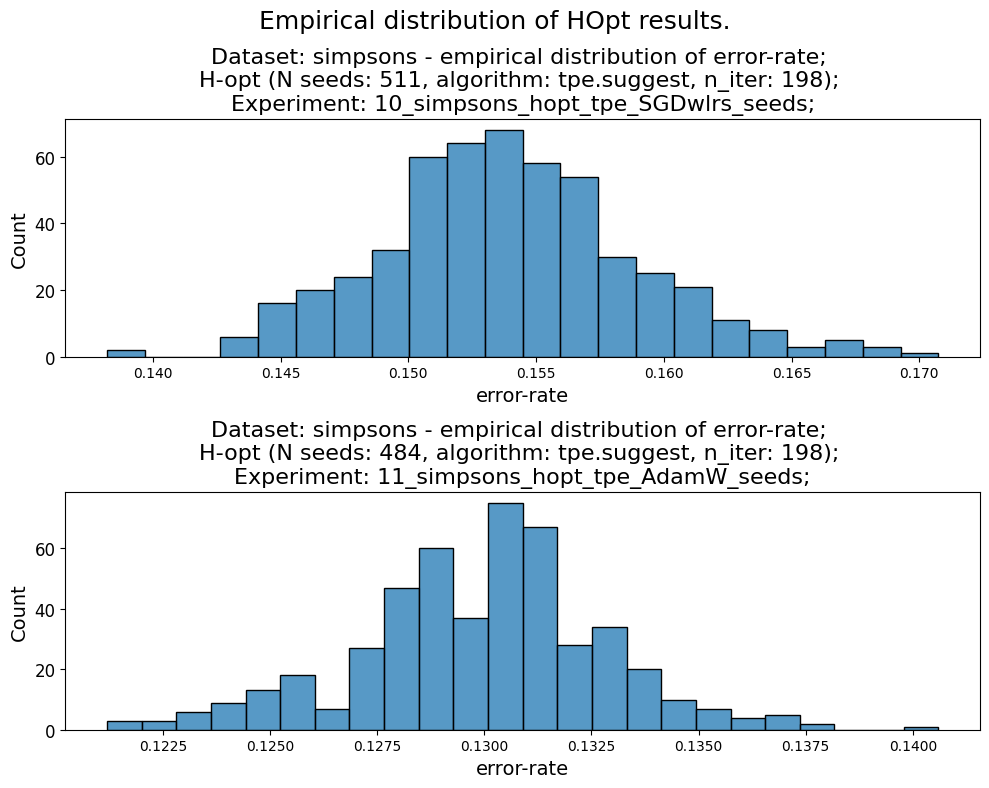

In [20]:
fig, axs = plt.subplots(nrows=len(EXPERIMENTS), figsize=(10, 4 * len(EXPERIMENTS)))
fig.suptitle("Empirical distribution of HOpt results.")
for (experiment, df_experiment), ax in zip(DF_RESULTS.groupby("experiment"), axs):
    df_experiment = df_experiment.sort_index()
    df_max_hopt_iter = df_experiment.reset_index(level="hopt_iter", drop=False).groupby(["experiment", "omniopt_seed"])["hopt_iter"].max()
    seeds_with_sufficient_evals = df_max_hopt_iter.loc[df_max_hopt_iter>=evals_thr].index.get_level_values("omniopt_seed")
    df_experiment = df_experiment.loc[pd.IndexSlice[:, seeds_with_sufficient_evals, :evals_thr]]
    df = df_experiment.groupby("omniopt_seed").min()
    visualization.hopt_results_plot.plot_metric_hist(
        df=df,
        experiment_name=experiment,
        dataset_name=DATASET_NAME,
        hopt_algorithm_name=ALGORITHM_NAME,
        n_iter=evals_thr,
        metric_name=METRIC,
        ax=ax,
        bins='auto'
    )
fig.tight_layout()